# Deviation Lollipop (from mean)

**Family:** Deviation &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Deviation:* Emphasise variations (+/-) from a fixed reference point: zero, a target, or an average.

## Design purpose

Each item is a dot joined by a thin stem to a reference value such as the group mean. It carries the same message as a diverging bar with much less ink, so it works well with many items.

## When to use

- Show how far each item sits from the average or target
- Show many categories, where solid bars would look heavy
- Highlight outliers relative to a benchmark

## Avoid when

- Values are very close together (stems become invisible)
- The audience expects conventional bar charts

## Alternatives

- Diverging bar chart
- Dot plot with a reference line

## Example

Fuel efficiency (mpg) of 20 car models compared with the fleet average.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(11)
models = [f"Model {i:02d}" for i in range(1, 21)]
mpg = rng.normal(28, 6, len(models)).round(1)
df = pd.DataFrame({"model": models, "mpg": mpg})
df["dev"] = df["mpg"] - df["mpg"].mean()
df = df.sort_values("dev").reset_index(drop=True)
df.head()

,model,mpg,dev
0,Model 10,16.9,-12.28
1,Model 06,24.8,-4.38
2,Model 04,24.9,-4.28
3,Model 15,25.7,-3.48
4,Model 05,26.2,-2.98


### Plot

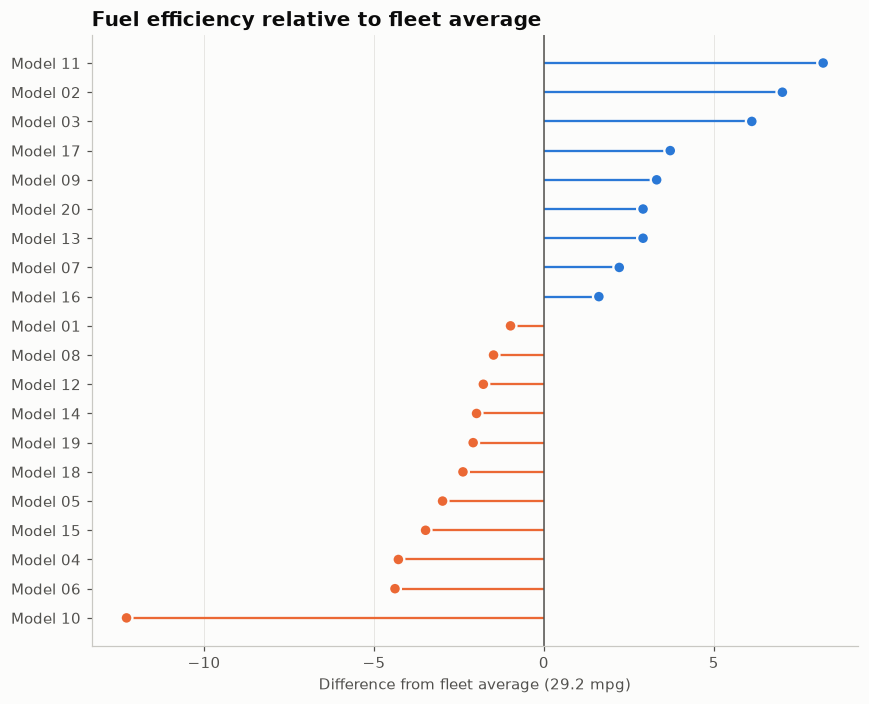

In [3]:
fig, ax = plt.subplots(figsize=(8, 6.5))
colors = np.where(df["dev"] >= 0, PALETTE[0], PALETTE[1])
ax.hlines(df.index, 0, df["dev"], color=colors, linewidth=1.5)
ax.scatter(df["dev"], df.index, color=colors, s=60, zorder=3,
           edgecolor="#fcfcfb", linewidth=1.5)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_yticks(df.index, df["model"])
ax.set_xlabel(f"Difference from fleet average ({df['mpg'].mean():.1f} mpg)")
ax.set_title("Fuel efficiency relative to fleet average")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

---
Standalone script: [`deviation_lollipop.py`](deviation_lollipop.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)